# Credit Card Default Prediction - Credit Card Clients

## Summary
- **Goal:** flag card customers likely to miss next month's payment, so a risk team can act first (call, payment plan, limit review).
- **Data:** UCI "Default of Credit Card Clients" (Taiwan, 2005) - 30,000 customers, 25 columns, ~22.1% defaulted.
- **Approach:** clean → explore → compare 6 models with 5-fold cross-validation → pick the best → tune the decision threshold for the business goal → test once on held-out data → check fairness across groups.
- **Result:** Gradient Boosting reaches **0.785 ROC-AUC in cross-validation and 0.782 on the held-out test set**. Lowering the decision threshold from 0.50 to ~0.25 raises the share of defaulters caught from **36% to 58%**.
- **Top default drivers:** a late payment last month, repeated late months, and how much of the bill gets paid.

## 1. Business problem
A bank loses money when a card holder stops paying. Acting early (a reminder call, a payment plan, pausing a limit increase) costs a little. A default costs a lot more.

So the model's job is to **rank customers by default risk** and hand the risk team a list.

**What matters when judging the model:**
- **ROC-AUC** - how well it ranks defaulters above non-defaulters. Used to compare models.
- **Recall on defaulters** - of the customers who really defaulted, how many did we catch? Missing one is the expensive mistake.
- **Precision on defaulters** - of the customers we flag, how many really default? Too low and the team wastes calls and upsets good customers.

Accuracy alone is misleading here: predicting "no one defaults" is already ~78% accurate.

## 2. Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, precision_recall_curve, recall_score, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

RANDOM_STATE = 42
DATA_PATH = "default of credit card clients.xls"   # file sits next to the notebook

## 3. Load and check the data
The Excel file has two header rows. The real column names are on the second row, so `header=1`.

In [2]:
df = pd.read_excel(DATA_PATH, header=1)
print("Shape:", df.shape)
df.head()

Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate rows ignoring ID:", df.drop(columns=["ID"]).duplicated().sum())
print("Total missing values:", df.isna().sum().sum())

Duplicate rows: 0
Duplicate rows ignoring ID: 35
Total missing values: 0


No missing values. 35 rows match another row once the ID is removed. They have different IDs, so they are likely different people with the same numbers (for example, unused cards with all-zero bills). That's 0.1% of rows, so I keep them.

**What the columns mean:**
- `LIMIT_BAL` - credit limit (NT dollars).
- `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` - customer profile.
- `PAY_0`, `PAY_2` … `PAY_6` - repayment status, most recent month first (Sept back to April). -2 = no balance to pay, -1 = paid in full, 0 = paid the minimum, 1-8 = months late.
- `BILL_AMT1-6` - bill amount each month. `PAY_AMT1-6` - amount paid each month.
- Target: `default payment next month` (1 = defaulted).

## 4. Cleaning
**Undocumented category codes.** The data guide lists EDUCATION as 1-4 and MARRIAGE as 1-3, but the data has extra codes.

In [5]:
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE: ", df["MARRIAGE"].value_counts().sort_index().to_dict())

EDUCATION: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE:  {0: 54, 1: 13659, 2: 15964, 3: 323}


EDUCATION codes 0, 5, 6 (345 rows) and MARRIAGE code 0 (54 rows) aren't in the data guide. I fold them into the existing "other" group (4 and 3). That's about 1% of rows.

In [6]:
df = df.rename(columns={"default payment next month": "DEFAULT", "PAY_0": "PAY_1"})   # PAY_1 so names line up with BILL_AMT1 / PAY_AMT1
df = df.drop(columns=["ID"])   # ID carries no information about behavior

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

# Make the codes readable (and so they get one-hot encoded, not treated as numbers)
df["SEX"] = df["SEX"].map({1: "Male", 2: "Female"})
df["EDUCATION"] = df["EDUCATION"].map({1: "Grad school", 2: "University", 3: "High school", 4: "Other"})
df["MARRIAGE"] = df["MARRIAGE"].map({1: "Married", 2: "Single", 3: "Other"})

print("Rows:", len(df))
print("Default rate: {:.1%}".format(df["DEFAULT"].mean()))

Rows: 30000
Default rate: 22.1%


**Features.** Three new columns that summarize six months of history in a way a person can read:
- `MONTHS_LATE` - how many of the last 6 months the customer was late (status ≥ 1).
- `UTILIZATION` - latest bill ÷ credit limit. How "maxed out" the card is.
- `PAY_RATIO` - total paid ÷ total billed over 6 months. Capped at 0-1 (a ratio above 1 just means they paid it all; it's 1 when there was nothing to pay).

In [7]:
pay_cols  = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
amt_cols  = [f"PAY_AMT{i}" for i in range(1, 7)]

df["MONTHS_LATE"] = (df[pay_cols] >= 1).sum(axis=1)
df["UTILIZATION"] = df["BILL_AMT1"] / df["LIMIT_BAL"]

total_bill = df[bill_cols].sum(axis=1)
total_paid = df[amt_cols].sum(axis=1)
df["PAY_RATIO"] = np.where(total_bill > 0, total_paid / total_bill.where(total_bill > 0), 1.0)
df["PAY_RATIO"] = df["PAY_RATIO"].clip(0, 1)

df[["MONTHS_LATE", "UTILIZATION", "PAY_RATIO"]].describe().round(2)

,MONTHS_LATE,UTILIZATION,PAY_RATIO
count,30000.00,30000.00,30000.00
mean,0.83,0.42,0.35
std,1.55,0.41,0.38
min,0.00,-0.62,0.00
25%,0.00,0.02,0.04
50%,0.00,0.31,0.11
75%,1.00,0.83,0.72
max,6.00,6.46,1.00


## 5. Exploratory analysis

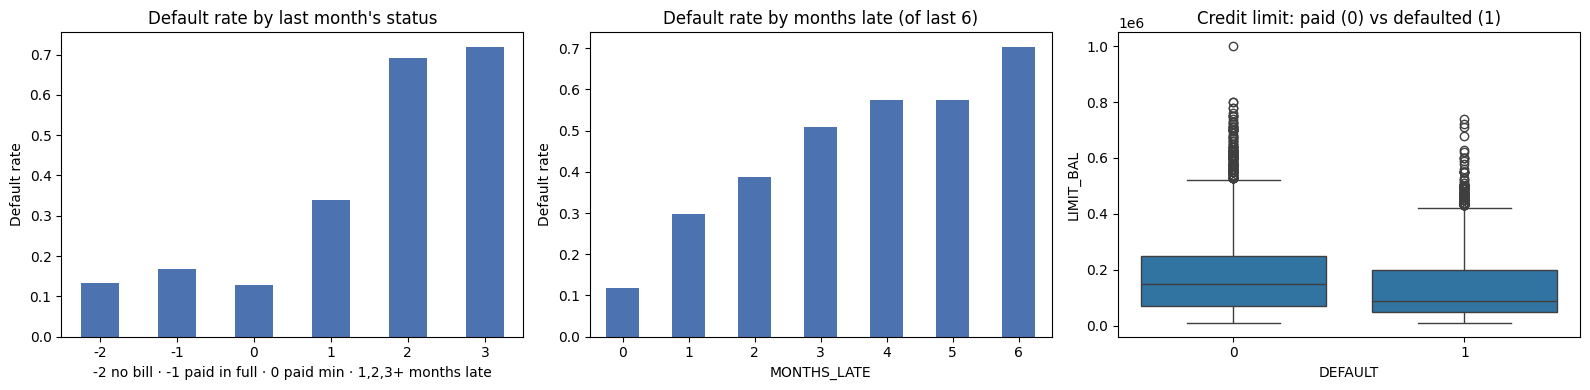

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

status = df["PAY_1"].clip(upper=3)   # group 3+ months late together (few rows)
df.groupby(status)["DEFAULT"].mean().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Default rate by last month's status")
axes[0].set_xlabel("-2 no bill · -1 paid in full · 0 paid min · 1,2,3+ months late")
axes[0].set_ylabel("Default rate")
axes[0].tick_params(axis="x", rotation=0)

df.groupby("MONTHS_LATE")["DEFAULT"].mean().plot.bar(ax=axes[1], color="#4C72B0")
axes[1].set_title("Default rate by months late (of last 6)")
axes[1].set_ylabel("Default rate")
axes[1].tick_params(axis="x", rotation=0)

sns.boxplot(data=df, x="DEFAULT", y="LIMIT_BAL", ax=axes[2])
axes[2].set_title("Credit limit: paid (0) vs defaulted (1)")

plt.tight_layout()
plt.show()

In [9]:
print(df.groupby(status)["DEFAULT"].mean().round(3), "\n")
print(df.groupby("MONTHS_LATE")["DEFAULT"].mean().round(3), "\n")
for col in ["EDUCATION", "MARRIAGE", "SEX"]:
    print(df.groupby(col)["DEFAULT"].mean().sort_values(ascending=False).round(3), "\n")

PAY_1
-2    0.132
-1    0.168
 0    0.128
 1    0.339
 2    0.691
 3    0.719
Name: DEFAULT, dtype: float64 

MONTHS_LATE
0    0.117
1    0.298
2    0.388
3    0.509
4    0.573
5    0.574
6    0.703
Name: DEFAULT, dtype: float64 

EDUCATION
High school    0.252
University     0.237
Grad school    0.192
Other          0.071
Name: DEFAULT, dtype: float64 

MARRIAGE
Other      0.236
Married    0.235
Single     0.209
Name: DEFAULT, dtype: float64 

SEX
Male      0.242
Female    0.208
Name: DEFAULT, dtype: float64 



**What the data says before any model:**
- **Last month's status is the strongest signal.** Customers who paid on time default about 13-17% of the time; 2+ months late, about 70%.
- Default risk climbs with every extra late month in the past six.
- Customers who default have lower credit limits on average (the bank already rated them as riskier).
- Profile columns (education, marriage, sex) show only small differences.

## 6. Train / test split
- 80% train, 20% test.
- **Stratified**, so both sets keep the same ~22% default rate.

**SEX and MARRIAGE are kept out of the model.** In the US, the Equal Credit Opportunity Act bars using sex or marital status in credit decisions. I keep the columns aside only to check fairness at the end (section 12).

In [10]:
PROTECTED = ["SEX", "MARRIAGE"]

X = df.drop(columns=["DEFAULT"] + PROTECTED)
y = df["DEFAULT"]
groups = df[PROTECTED]

X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " default rate {:.1%}".format(y_train.mean()))
print("Test: ", X_test.shape, " default rate {:.1%}".format(y_test.mean()))

Train: (24000, 24)  default rate 22.1%
Test:  (6000, 24)  default rate 22.1%


## 7. Preprocessing
- **Numbers** (limit, age, repayment status, bills, payments, new features) → scaled. Matters for Logistic Regression; harmless for trees.
- **Categories** (education) → one-hot encoded.
- Everything sits inside a **Pipeline**, so scaling is learned from training folds only.

In [11]:
cat_cols = X.select_dtypes(include=["object", "category"]).columns
num_cols = X.select_dtypes(exclude=["object", "category"]).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], sparse_threshold=0)   # always return a dense table (Naive Bayes needs it)

print("Numeric:", list(num_cols))
print("Categorical:", list(cat_cols))

Numeric: ['LIMIT_BAL', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'MONTHS_LATE', 'UTILIZATION', 'PAY_RATIO']
Categorical: ['EDUCATION']


## 8. Compare models with 5-fold cross-validation
Each model is scored on ROC-AUC across 5 folds of the **training** data.

Naive Bayes is a fast probability model that assumes features are independent. It's a useful simple baseline.

The Voting model combines Logistic Regression, Random Forest and Gradient Boosting by averaging their predicted probabilities (soft voting).

I left out SVM here: with 24,000 training rows and probability output it is very slow, and it was not a top model on the churn project.

In [12]:
def make_pipeline(model):
    return Pipeline([("preprocessor", preprocessor), ("model", model)])

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
}

models = dict(base_models)
models["Voting (soft)"] = VotingClassifier(
    estimators=[
        ("lr", base_models["Logistic Regression"]),
        ("rf", base_models["Random Forest"]),
        ("gb", base_models["Gradient Boosting"]),
    ],
    voting="soft",
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    scores = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    rows.append({"Model": name, "CV ROC-AUC (mean)": scores.mean(), "± std": scores.std()})

cv_results = pd.DataFrame(rows).sort_values("CV ROC-AUC (mean)", ascending=False).reset_index(drop=True)
cv_results.round(4)

,Model,CV ROC-AUC (mean),± std
0,Gradient Boosting,0.7849,0.0043
1,Voting (soft),0.7818,0.0050
2,Random Forest,0.7626,0.0039
3,Logistic Regression,0.7571,0.0080
4,Naive Bayes,0.7305,0.0115
5,Decision Tree,0.6122,0.0064


In [13]:
best_name = "Gradient Boosting"
print("Top score:", cv_results.loc[0, "Model"], round(cv_results.loc[0, "CV ROC-AUC (mean)"], 4))
print("Chosen model:", best_name)

Top score: Gradient Boosting 0.7849
Chosen model: Gradient Boosting


**Why Gradient Boosting?**
It has the best score (0.785) and the smallest spread across folds. Voting is close behind (0.781), but it runs three models and is harder to explain, so it isn't worth it.

Logistic Regression (0.757) is a clear step down here. That makes sense: risk jumps sharply once a customer is late (a curve, not a straight line), and trees pick that up on their own.

The single Decision Tree (0.613) overfits. With no depth limit it memorizes the training data.

## 9. Choose the decision threshold
By default a model flags a customer when predicted risk > 0.5. With only ~22% defaulters, that cutoff misses many of them.

I pick the threshold on training data only (out-of-fold predictions from cross-validation), so the test set stays untouched.

Rule: the highest threshold that still catches at least 60% of defaulters. That's a business choice. It can move up or down depending on what a missed default costs vs an unneeded call.

In [14]:
best_pipeline = make_pipeline(models[best_name])

oof_prob = cross_val_predict(best_pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)

TARGET_RECALL = 0.60
ok = recall[:-1] >= TARGET_RECALL
threshold = thresholds[ok].max()
print(f"Chosen threshold: {threshold:.3f}")
print(f"On training folds -> recall {recall[:-1][ok][-1]:.2f}, precision {precision[:-1][ok][-1]:.2f}")

Chosen threshold: 0.251
On training folds -> recall 0.60, precision 0.50


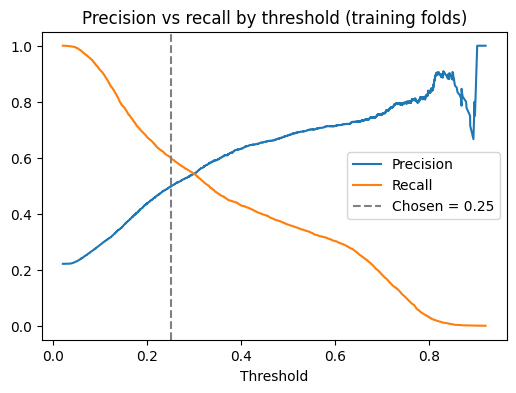

In [15]:
plt.figure(figsize=(6, 4))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.axvline(threshold, color="gray", linestyle="--", label=f"Chosen = {threshold:.2f}")
plt.xlabel("Threshold")
plt.title("Precision vs recall by threshold (training folds)")
plt.legend()
plt.show()

## 10. Final test

Test ROC-AUC: 0.782
Test PR-AUC:  0.557   (baseline = default rate 0.221)

--- Threshold Default 0.50 ---
              precision    recall  f1-score   support

        Paid       0.84      0.95      0.89      4673
   Defaulted       0.67      0.36      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000


--- Threshold Tuned 0.25 ---
              precision    recall  f1-score   support

        Paid       0.88      0.83      0.85      4673
   Defaulted       0.49      0.58      0.53      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.77      0.78      6000



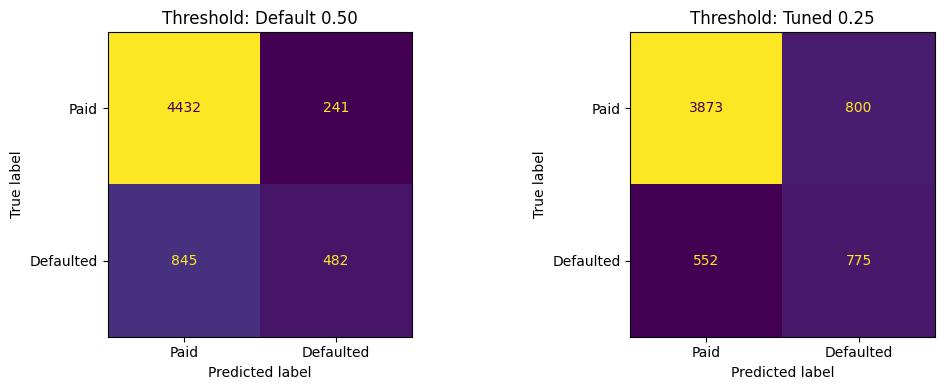

In [16]:
best_pipeline.fit(X_train, y_train)
test_prob = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test ROC-AUC: {roc_auc_score(y_test, test_prob):.3f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, test_prob):.3f}   (baseline = default rate {y_test.mean():.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, t) in zip(axes, [("Default 0.50", 0.5), (f"Tuned {threshold:.2f}", threshold)]):
    pred = (test_prob >= t).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Paid", "Defaulted"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"Threshold: {label}")
    print(f"\n--- Threshold {label} ---")
    print(classification_report(y_test, pred, target_names=["Paid", "Defaulted"], digits=2))
plt.tight_layout()
plt.show()

**Reading the result:**
- Test ROC-AUC (0.782) is close to cross-validation (0.785), so the model isn't overfitting.
- PR-AUC is 0.56 vs a 0.22 baseline, far better than guessing.
- At the default 0.50 cutoff the model catches only about 1 in 3 defaulters. At the tuned ~0.25 cutoff it catches close to 6 in 10, while about half of flagged customers really default.
- Why stop at 60% and not 75% like a churn model? On the training folds, catching 75% would mean flagging 44% of all customers with only 38% precision. That's too many calls for this data.

## 11. What drives default?

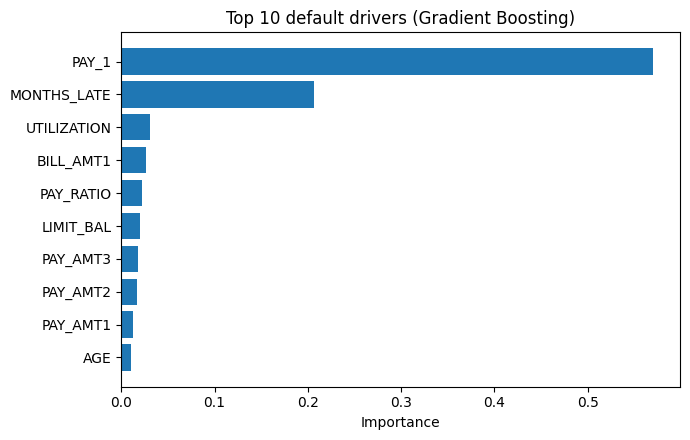

,Feature,Importance
2,PAY_1,0.571
20,MONTHS_LATE,0.207
21,UTILIZATION,0.031
8,BILL_AMT1,0.027
22,PAY_RATIO,0.022
0,LIMIT_BAL,0.020
16,PAY_AMT3,0.018
15,PAY_AMT2,0.016
14,PAY_AMT1,0.013
1,AGE,0.010


In [17]:
model = best_pipeline.named_steps["model"]
names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()

drivers = pd.DataFrame({"Feature": names, "Importance": model.feature_importances_})
drivers = drivers.sort_values("Importance", ascending=False).head(10)
drivers["Feature"] = drivers["Feature"].str.replace("num__", "").str.replace("cat__", "")

plt.figure(figsize=(7, 4.5))
plt.barh(drivers["Feature"], drivers["Importance"])
plt.gca().invert_yaxis()
plt.title("Top 10 default drivers (Gradient Boosting)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
drivers.round(3)

These match the exploratory charts: **last month's repayment status and the number of late months** carry most of the weight. Utilization, the latest bill, the share of the bill paid, and the credit limit add the rest.

Note: importance shows what the model leans on, not cause and effect.

## 12. Fairness check
SEX and MARRIAGE were never given to the model. But other columns can stand in for them, so I check the results by group on the test set at the tuned threshold.

- **Flag rate** - share of the group the model flags.
- **Recall** - share of the group's real defaulters the model catches.

Big gaps in recall would mean the model protects one group's defaulters better than another's.

In [18]:
test_pred = (test_prob >= threshold).astype(int)
check = pd.DataFrame({"y": y_test.values, "pred": test_pred,
                      "SEX": g_test["SEX"].values, "MARRIAGE": g_test["MARRIAGE"].values})

for col in ["SEX", "MARRIAGE"]:
    out = check.groupby(col).apply(lambda g: pd.Series({
        "Customers": len(g),
        "Default rate": g["y"].mean(),
        "Flag rate": g["pred"].mean(),
        "Recall": recall_score(g["y"], g["pred"]),
    }), include_groups=False)
    print(out.round(3), "\n")

        Customers  Default rate  Flag rate  Recall
SEX                                               
Female     3598.0         0.213      0.247   0.576
Male       2402.0         0.234      0.286   0.595 

          Customers  Default rate  Flag rate  Recall
MARRIAGE                                            
Married      2767.0         0.241      0.270   0.588
Other          75.0         0.160      0.267   0.500
Single       3158.0         0.205      0.256   0.581 



**Reading the check:** flag rates and recall are close across groups (recall 0.58 for women vs 0.60 for men). Men are flagged a bit more often, which follows their higher real default rate (23.4% vs 21.3%). The "Other" marriage group is only 75 people, too small to judge.

This is a first check, not a full audit. A real lender would also test approval outcomes and other protected groups (age, for example).

## 13. Business takeaways
1. **Act on last month first.** A customer who just went late is the highest-risk group. A quick reminder or payment-plan offer is cheap compared to a default.
2. **Watch the pattern, not one month.** Repeated late months and paying back only a small share of the bill are early warning signs, even before a customer is badly behind.
3. **Use the ranked list, not just yes/no.** The risk team can work from the top of the list down as staff time allows, and move the cutoff when the cost of a call or a default changes.

**Next steps:** tune Gradient Boosting's settings inside cross-validation, try a time-based check (train on older months, test on newer), and price the cutoff with real costs.